In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd 
import scipy.constants as spc 
from scipy.optimize import curve_fit
import os
from edes.utils.plotting import plot, plot_ax, plot_ax_errbar, big_plt_font, nemo_plt_font, two_row_figs, wide_four_figs
from edes.utils.circuits import W_to_dBm, dBm_to_W
from edes.modules.detection.detection_utils import AnharmonicElectronCoupledTankWithMatch, Amplifier
big_plt_font()
# nemo_plt_font()

blue = '#004AAE'
gold = '#FFC31B'
green = '#018943'
dark_red = '#A00000'
red = '#E7115E'
purple = '#8236C7'
light_blue = '#9FD1FF'
light_gold = '#FFE88D'
light_red = '#FFCFE5'
light_purple = '#D9CEFF'
light_green = '#B3E59A'
black = 'k'

In [2]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
from tqdm import trange
import edes.modules.detection.detection_utils as utils
from edes.modules.detection.detection_utils import e, m, kB 
from edes.modules.detection.detection_utils import plot, plot_ax, plot_errbar, plot_power_spectrum, big_plt_font
from edes.modules.detection.detection_utils import W_to_dBm, dBm_to_W, dB_to_frac, frac_to_dB, voltage_noise_to_dBm
from edes.modules.detection.detection_utils import find_width, moving_avg
from edes.modules.detection.detection_utils import Component, DetectionSetup
from edes.modules.detection.detection_utils import BandPassFilter, SpectrumAnalyzer, Amplifier
from edes.modules.detection.detection_utils import HarmonicElectron, TankCircuit
from edes.modules.detection.detection_utils import HarmonicElectronCoupledTank, ElectronCoupledToTank
from edes.modules.detection.detection_utils import AnharmonicElectronSetup
from edes.modules.detection.detection_utils import parallel

class AnharmonicElectron(HarmonicElectron): 
    def __init__(self, n, d, omega, Qe, Te=4, m=m, e=e, name='Hot_electron'): 
        super().__init__(n, d, omega, m=m, e=e, name=name) 
        self.r = np.sqrt(self.l/self.c) / Qe 
        self.Qe = Qe 
        self.Te = Te 

    def get_noise(self, f): 
        PSD = 4*kB*self.Te*self.r
        return PSD

    def get_rlc(self): 
        return self.r, self.l, self.c

class TankCircuitPinMatchedAmp(TankCircuit): 
    def __init__(self, Q, Z0, omega_0, Cc, ZL, Tr=4, Ta=4, name='TankCircuit'): 
        super().__init__(Q, Z0, omega_0, T=Tr) 
        self.T = Tr 
        self.Tr = Tr 
        self.Ta = Ta 
        self.Cc = Cc 
        self.Zload = ZL 

    def get_noise_tank(self, f): 
        return super().get_noise(f) 

    def get_noise_amp(self, f): 
        PSD = 4*kB*self.Ta*self.Zload
        return PSD

class TankCircuitAbstractMatched(TankCircuit): 
    def __init__(self, Q, Z0, omega_0, match_loss, ZL, Tr=4, Ta=4, name='TankCircuit'): 
        super().__init__(Q, Z0, omega_0, T=Tr) 
        self.T = Tr 
        self.Tr = Tr 
        self.Ta = Ta 
        self.match_loss = match_loss 
        self.Zload = ZL 

    def get_noise_tank(self, f): 
        return 4*kB*self.Tr*self.Z0*self.Q

    def get_noise_amp(self, f): 
        PSD = 4*kB*self.Ta*self.Zload
        return PSD

class AnharmonicElectronCoupledTankWithMatch(Component): 
    def __init__(self, n, d, Qr, Qe, Z0, omega_0, omega_z, matching_loss,
                 m=m, e=e, Tr=4, Te=4, Ta=4, ZL=50,
                 name='Electron'):
        super().__init__(name=name, n=n, d=d, Qe=Qe, Qr=Qr, Z0=Z0,
                         omega_0=omega_0, omega_z=omega_z, matching_loss=matching_loss,
                         Tr=Tr, Te=Te, Ta=Ta, ZL=ZL, m=m, e=e)
        self.Electron = AnharmonicElectron(n, d, omega_z, Qe, Te, m, e, name)
        self.TankCircuit = TankCircuitAbstractMatched(Qr, Z0, omega_0, matching_loss, ZL, 
                                                    Tr, Ta, name)
        self.R, self.L, self.C = self.TankCircuit.get_RLC()
        self.r, self.l, self.c = self.Electron.get_rlc()
        
    def Hr(self, omega):
        '''
        series rlc (electron) coupled to a parallel RLC (tank circuit) 
        circuit, see Wineland 1975
        '''
        s = 1j*omega
        s = 1j*omega
        Zl = s*self.l
        ZL = s*self.L
        Zc = 1/(s*self.c)
        ZC = 1/(s*self.C)
        R = self.R
        r = self.r
        
        Zlc = parallel( (Zl+Zc+r), parallel(ZL, ZC) )
        return (Zlc / (Zlc+R))
    

    def He(self, omega): 
        s = 1j*omega
        s = 1j*omega
        Zl = s*self.l
        ZL = s*self.L
        Zc = 1/(s*self.c)
        ZC = 1/(s*self.C)
        R = self.R
        r = self.r
        
        Z_tank = parallel( R, parallel(ZL, ZC) )
        Z_ele = r + Zl + Zc
        return (Z_tank / (Z_tank+Z_ele))

    def __call__(self, freq): 
        tank_noise = self.TankCircuit.get_noise_tank(freq)
        amp_noise = self.TankCircuit.get_noise_amp(freq)
        ele_noise = self.Electron.get_noise(freq)
        omega = 2*np.pi*freq 
        # print((abs(self.He(omega))**2 * abs(ele_noise)), abs(self.Hr(omega))**2 * abs(tank_noise))
        return (abs(self.He(omega))**2 * abs(ele_noise) + \
               abs(self.Hr(omega))**2 * abs(tank_noise)) / self.matching_loss +  \
               abs(amp_noise)

class HotElectronSetup(DetectionSetup):
    def __init__(self, n, d, Qr, Qe, matching_loss, Z0, f0, fz_0, 
                 Te, Tr, Ta,
                 BW_measurement, Z_measurement, noise_floor, 
                 N_average, m=m, e=e,
                 devices=[],
                 display_progress=False, 
		         display_averaging=False,
                 name='AnharmonicElectron'):
        
        super().__init__(BW_measurement, Z_measurement, noise_floor, 
                         name=name, n=n, d=d, Qr=Qr, Z0=Z0, f0=f0, 
                         fz_0=fz_0, Qe=Qe, Tr=Tr, Ta=Ta,
                         m=m, e=e, Te=Te, N_average=N_average,
                         display_progress=display_progress)
        self.devices = devices
        self.electron = AnharmonicElectronCoupledTankWithMatch(
                            n, d, Qr, Qe, Z0, 
                            2*np.pi*f0, 2*np.pi*fz_0, matching_loss,
                            m=m, e=e, Tr=Tr, Te=Te, Ta=Ta, ZL=Z_measurement)
        self.display_averaging = display_averaging

    def __call__(self, freq):
        spectrum = np.zeros(np.shape(freq))
        N_average = self.N_average
        
        psd_signal = self.electron(freq)
            
        for device in self.devices:
            psd_signal = device(freq, psd_signal)

        spectrum += psd_signal / N_average
        return W_to_dBm(spectrum*self.BW_measurement/self.Z_measurement)

In [3]:
data_path = 'C:\\Users\\andrish\\Downloads/rfsoc_data_event_11117.npz' 
data_file = np.load(data_path) 
signal_f_1, signal_p_1 = data_file['signal_f_1'], data_file['signal_p_1']
signal_f_2, signal_p_2 = data_file['signal_f_2'], data_file['signal_p_2'] 
signal_f_3, signal_p_3 = data_file['signal_f_3'], data_file['signal_p_3'] 
noise_f, noise_p = data_file['noise_f'], data_file['noise_p']

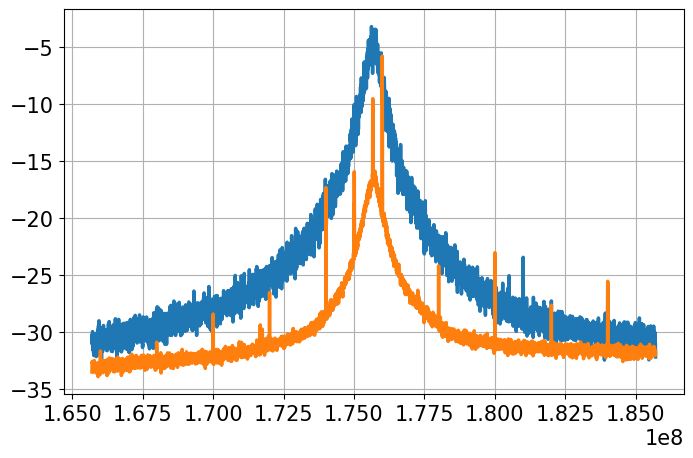

In [4]:
plot(signal_f_2, W_to_dBm(signal_p_2*1e-3))
plot(noise_f, W_to_dBm(noise_p*1e-3))

In [5]:

# span = 20e6
# f0 = 175.7e6
# freq = np.linspace(f0-span/2, f0+span/2, int(span)//10) 

def get_noise_spectrum_loss(freq, loss, gain_dB, Qr):
    n = 1
    d = 4.8e-3
    # Qr = 300 
    Qe = 1 
    # loss = 10
    Cr = 2.97e-12 
    f0 = 175.7e6 
    Z0 = 1/(2*np.pi*f0 * Cr)
    fz_0 = 170.7e6 
    Te = 0.1
    Tr = 10
    Ta = 55 
    BW_measurement = 5000
    Z_measurement = 50 
    noise_floor = 1e-20 
    N_average = 1 
    display_averaging = 0
    
    
    
    G_preamp = 10**(gain_dB/20)
    pre_amp = Amplifier(G_preamp, 0)
    devices = [pre_amp]
    
    
    setup = HotElectronSetup(n, d, Qr, Qe, loss, Z0, f0, fz_0, 
                     Te, Tr, Ta,
                     BW_measurement, Z_measurement, noise_floor, 
                     N_average, m=m, e=e,
                     devices=devices,
    		         display_averaging=display_averaging)
    return setup(freq)

def get_noise_spectrum(freq, Ta, gain_dB, Qr):
    n = 1
    d = 4.8e-3
    # Qr = 300 
    Qe = 1 
    loss = 1
    Cr = 2.97e-12 
    f0 = 175.7e6 
    Z0 = 1/(2*np.pi*f0 * Cr)
    fz_0 = 170.7e6 
    Te = 0.1
    Tr = 10
    # Ta = 55 
    BW_measurement = 5000
    Z_measurement = 50 
    noise_floor = 1e-30 
    N_average = 1 
    display_averaging = 0
    
    
    
    G_preamp = 10**(gain_dB/20)
    pre_amp = Amplifier(G_preamp, 0)
    devices = [pre_amp]
    
    
    setup = HotElectronSetup(n, d, Qr, Qe, loss, Z0, f0, fz_0, 
                     Te, Tr, Ta,
                     BW_measurement, Z_measurement, noise_floor, 
                     N_average, m=m, e=e,
                     devices=devices,
    		         display_averaging=display_averaging)
    return setup(freq)

def get_signal_spectrum_loss(freq, n, Te, fz_0, Qe, loss=10, gain_dB=100, Qr=300):
    # n = 100000
    d = 4.8e-3
    # Qr = 300 
    # Qe = 15 
    # loss = 10
    Cr = 2.97e-12 
    f0 = 175.7e6 
    Z0 = 1/(2*np.pi*f0 * Cr)
    # fz_0 = 170.7e6 
    # Te = 10000
    Tr = 10
    Ta = 55 
    BW_measurement = 5000
    Z_measurement = 50 
    noise_floor = 1e-20 
    N_average = 1 
    display_averaging = 0
    # gain_dB = 103
    
    
    G_preamp = 10**(gain_dB/20)
    pre_amp = Amplifier(G_preamp, 0)
    devices = [pre_amp]
    
    setup = HotElectronSetup(n, d, Qr, Qe, loss, Z0, f0, fz_0*1e6, 
                     Te, Tr, Ta,
                     BW_measurement, Z_measurement, noise_floor, 
                     N_average, m=m, e=e,
                     devices=devices,
    		         display_averaging=display_averaging)
    return setup(freq)

def get_signal_spectrum(freq, n, Te, fz_0, Qe, Ta=55, gain_dB=100, Qr=300):
    # n = 100000
    d = 4.8e-3
    # Qr = 300 
    # Qe = 15 
    loss = 1
    Cr = 2.97e-12 
    f0 = 175.7e6 
    Z0 = 1/(2*np.pi*f0 * Cr)
    # fz_0 = 170.7e6 
    # Te = 10000
    Tr = 10
    # Ta = 55 
    BW_measurement = 5000
    Z_measurement = 50 
    noise_floor = 1e-20 
    N_average = 1 
    display_averaging = 0
    # gain_dB = 103
    
    
    G_preamp = 10**(gain_dB/20)
    pre_amp = Amplifier(G_preamp, 0)
    devices = [pre_amp]
    
    setup = HotElectronSetup(n, d, Qr, Qe, loss, Z0, f0, fz_0*1e6, 
                     Te, Tr, Ta,
                     BW_measurement, Z_measurement, noise_floor, 
                     N_average, m=m, e=e,
                     devices=devices,
    		         display_averaging=display_averaging)
    return setup(freq)

In [6]:
Cr = 2.97e-12 
f0 = 175.7e6 
Z0 = 1/(2*np.pi*f0 * Cr)
Z0*900

274494.9950706186

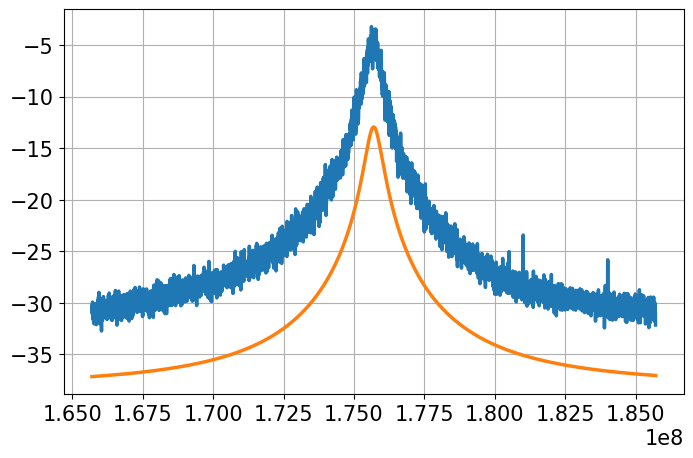

In [7]:
plot(signal_f_2, W_to_dBm(signal_p_2*1e-3)) 
plot(signal_f_2, get_signal_spectrum(noise_f, 2000000, 100000000000000, 175.7e6,1))

In [8]:
def fit(func, freq, P, p0, bounds=(-np.inf, np.inf), sigma=None):
    popt, pcov = curve_fit(func, freq, P, p0=p0, bounds=bounds, sigma=sigma,
                           absolute_sigma=sigma is not None, maxfev=100000)
    perr = np.sqrt(np.diag(pcov))
    return popt, perr, pcov

In [9]:
import numpy as np
from scipy.optimize import curve_fit, differential_evolution

def fit_db(model, freq, P, p0, lo, hi, model_in_db=True, data_in_db=True,
           n_restarts=0):
    freq = np.asarray(freq, float)
    y = np.asarray(P, float)
    if not data_in_db:
        y = 10*np.log10(y)
    good = np.isfinite(y)
    freq, y = freq[good], y[good]

    p0 = np.asarray(p0, float)
    lo = np.broadcast_to(np.asarray(lo, float), p0.shape).copy()
    hi = np.broadcast_to(np.asarray(hi, float), p0.shape).copy()

    def f_db(x, *p):
        m = np.asarray(model(x, *p), float)
        if not model_in_db:
            m = 10*np.log10(np.where(np.isfinite(m) & (m > 0), m, 1e-300))
        return np.where(np.isfinite(m), m, 1e3)

    def cost(p):
        return np.sum((f_db(freq, *p) - y)**2)

    if n_restarts:
        p0 = differential_evolution(cost, list(zip(lo, hi)), seed=0,
                                    maxiter=n_restarts, polish=False,
                                    tol=1e-8).x

    popt, pcov = curve_fit(f_db, freq, y, p0=p0, bounds=(lo, hi),
                           x_scale='jac', method='trf', maxfev=200000)
    resid = f_db(freq, *popt) - y
    s2 = np.sum(resid**2) / (len(y) - len(popt))
    return popt, np.sqrt(np.diag(pcov)), pcov, np.sqrt(s2)

In [10]:
popt_noise, perr_noise, pcov, rms = fit_db(
    get_noise_spectrum, noise_f, noise_p,
    p0=[55, 103, 300],
    lo=[1, 80, 100],
    hi=[1000, 120, 1000],
    data_in_db=False,
    n_restarts=200)

c:\users\andrish\edes\edes\modules\detection\detection_utils.py:94: RuntimeWarning: divide by zero encountered in divide
  return 1/(1/a+1/b)
c:\users\andrish\edes\edes\modules\detection\detection_utils.py:94: RuntimeWarning: invalid value encountered in divide
  return 1/(1/a+1/b)
C:\Users\andrish\AppData\Local\Temp\ipykernel_12432\3394408892.py:106: RuntimeWarning: invalid value encountered in divide
  return (Z_tank / (Z_tank+Z_ele))
C:\Users\andrish\AppData\Local\Temp\ipykernel_12432\3394408892.py:91: RuntimeWarning: invalid value encountered in divide
  return (Zlc / (Zlc+R))


In [11]:
popt_noise

array([421.93432736,  96.99002108, 236.97912736])

In [10]:
class AnharmonicElectronCoupledTankWithMatch(Component): 
    def __init__(self, n, d, Qr, Qe, Z0, omega_0, omega_z, matching_loss,
                 m=m, e=e, Tr=4, Te=4, Ta=4, ZL=50,
                 corr_amp=0, corr_phase=0, tilt_dB_per_MHz=0,
                 name='Electron'):
        super().__init__(name=name, n=n, d=d, Qe=Qe, Qr=Qr, Z0=Z0,
                         omega_0=omega_0, omega_z=omega_z, matching_loss=matching_loss,
                         Tr=Tr, Te=Te, Ta=Ta, ZL=ZL, m=m, e=e)
        self.Electron = AnharmonicElectron(n, d, omega_z, Qe, Te, m, e, name)
        self.TankCircuit = TankCircuitAbstractMatched(Qr, Z0, omega_0, matching_loss, ZL, 
                                                    Tr, Ta, name)
        self.R, self.L, self.C = self.TankCircuit.get_RLC()
        self.r, self.l, self.c = self.Electron.get_rlc()
        self.omega_0 = omega_0
        self.corr_amp = corr_amp
        self.corr_phase = corr_phase
        self.tilt = tilt_dB_per_MHz

    def Hr(self, omega):
        s = 1j*omega
        Zl = s*self.l
        ZL = s*self.L
        Zc = 1/(s*self.c)
        ZC = 1/(s*self.C)
        R = self.R
        r = self.r
        Zlc = parallel((Zl+Zc+r), parallel(ZL, ZC))
        return Zlc / (Zlc+R)

    def He(self, omega): 
        s = 1j*omega
        s = 1j*omega
        Zl = s*self.l
        ZL = s*self.L
        Zc = 1/(s*self.c)
        ZC = 1/(s*self.C)
        R = self.R
        r = self.r
        
        Z_tank = parallel( R, parallel(ZL, ZC) )
        Z_ele = r + Zl + Zc
        return (Z_tank / (Z_tank+Z_ele))

    def Hamp(self, omega):
        return 1 + self.corr_amp*np.exp(1j*self.corr_phase)*self.Hr(omega)

    def gain_tilt(self, omega):
        return 10**(self.tilt*(omega - self.omega_0)/(2*np.pi*1e6)/10)

    def __call__(self, freq): 
        tank_noise = self.TankCircuit.get_noise_tank(freq)
        amp_noise = self.TankCircuit.get_noise_amp(freq)
        ele_noise = self.Electron.get_noise(freq)
        omega = 2*np.pi*freq 
        return self.gain_tilt(omega) * (
            (abs(self.He(omega))**2 * abs(ele_noise) +
             abs(self.Hr(omega))**2 * abs(tank_noise)) / self.matching_loss +
            abs(self.Hamp(omega))**2 * abs(amp_noise))


class HotElectronSetup(DetectionSetup):
    def __init__(self, n, d, Qr, Qe, matching_loss, Z0, f0, fz_0, 
                 Te, Tr, Ta,
                 BW_measurement, Z_measurement, noise_floor, 
                 N_average, m=m, e=e,
                 devices=[],
                 display_progress=False, 
                 display_averaging=False,
                 corr_amp=0, corr_phase=0, tilt_dB_per_MHz=0,
                 name='AnharmonicElectron'):
        super().__init__(BW_measurement, Z_measurement, noise_floor, 
                         name=name, n=n, d=d, Qr=Qr, Z0=Z0, f0=f0, 
                         fz_0=fz_0, Qe=Qe, Tr=Tr, Ta=Ta,
                         m=m, e=e, Te=Te, N_average=N_average,
                         display_progress=display_progress)
        self.devices = devices
        self.electron = AnharmonicElectronCoupledTankWithMatch(
                            n, d, Qr, Qe, Z0, 
                            2*np.pi*f0, 2*np.pi*fz_0, matching_loss,
                            m=m, e=e, Tr=Tr, Te=Te, Ta=Ta, ZL=Z_measurement,
                            corr_amp=corr_amp, corr_phase=corr_phase,
                            tilt_dB_per_MHz=tilt_dB_per_MHz)
        self.display_averaging = display_averaging

    def __call__(self, freq):
        spectrum = np.zeros(np.shape(freq))
        N_average = self.N_average
        psd_signal = self.electron(freq)
        for device in self.devices:
            psd_signal = device(freq, psd_signal)
        spectrum += psd_signal / N_average
        return W_to_dBm(spectrum*self.BW_measurement/self.Z_measurement)


def get_noise_spectrum(freq, Ta, gain_dB, Qr, corr_amp, corr_phase, tilt_dB_per_MHz):
    n = 1
    d = 4.8e-3
    Qe = 1 
    loss = 1
    Cr = 2.97e-12 
    f0 = 175.7e6 
    Z0 = 1/(2*np.pi*f0 * Cr)
    fz_0 = 170.7e6 
    Te = 0.1
    Tr = 10
    BW_measurement = 5000
    Z_measurement = 50 
    noise_floor = 1e-30 
    N_average = 1 
    display_averaging = 0

    G_preamp = 10**(gain_dB/20)
    pre_amp = Amplifier(G_preamp, 0)
    devices = [pre_amp]

    setup = HotElectronSetup(n, d, Qr, Qe, loss, Z0, f0, fz_0, 
                     Te, Tr, Ta,
                     BW_measurement, Z_measurement, noise_floor, 
                     N_average, m=m, e=e,
                     devices=devices,
                     display_averaging=display_averaging,
                     corr_amp=corr_amp, corr_phase=corr_phase,
                     tilt_dB_per_MHz=tilt_dB_per_MHz)
    return setup(freq)

def get_signal_spectrum(freq, n, Te, fz_0, Qe, Ta=55, gain_dB=100, Qr=300,
                        corr_amp=0, corr_phase=0, tilt_dB_per_MHz=0):
    d = 4.8e-3
    loss = 1
    Cr = 2.97e-12 
    f0 = 175.7e6 
    Z0 = 1/(2*np.pi*f0 * Cr)
    Tr = 10
    BW_measurement = 5000
    Z_measurement = 50 
    noise_floor = 1e-20 
    N_average = 1 
    display_averaging = 0

    G_preamp = 10**(gain_dB/20)
    pre_amp = Amplifier(G_preamp, 0)
    devices = [pre_amp]

    setup = HotElectronSetup(n, d, Qr, Qe, loss, Z0, f0, fz_0*1e6, 
                     Te, Tr, Ta,
                     BW_measurement, Z_measurement, noise_floor, 
                     N_average, m=m, e=e,
                     devices=devices,
                     display_averaging=display_averaging,
                     corr_amp=corr_amp, corr_phase=corr_phase,
                     tilt_dB_per_MHz=tilt_dB_per_MHz)
    return setup(freq)

In [11]:
popt_noise, perr_noise, pcov, rms = fit_db(
    get_noise_spectrum, noise_f, noise_p,
    p0=[55, 103, 300, 1, 0, 0],
    lo=[1, 80, 100, 0, -np.pi, -0.2],
    hi=[1000, 120, 1000, 20, np.pi, 0.2],
    data_in_db=False,
    n_restarts=200)

c:\users\andrish\edes\edes\modules\detection\detection_utils.py:94: RuntimeWarning: divide by zero encountered in divide
  return 1/(1/a+1/b)
c:\users\andrish\edes\edes\modules\detection\detection_utils.py:94: RuntimeWarning: invalid value encountered in divide
  return 1/(1/a+1/b)
C:\Users\andrish\AppData\Local\Temp\ipykernel_12992\2171722989.py:42: RuntimeWarning: invalid value encountered in divide
  return (Z_tank / (Z_tank+Z_ele))
C:\Users\andrish\AppData\Local\Temp\ipykernel_12992\2171722989.py:28: RuntimeWarning: invalid value encountered in divide
  return Zlc / (Zlc+R)


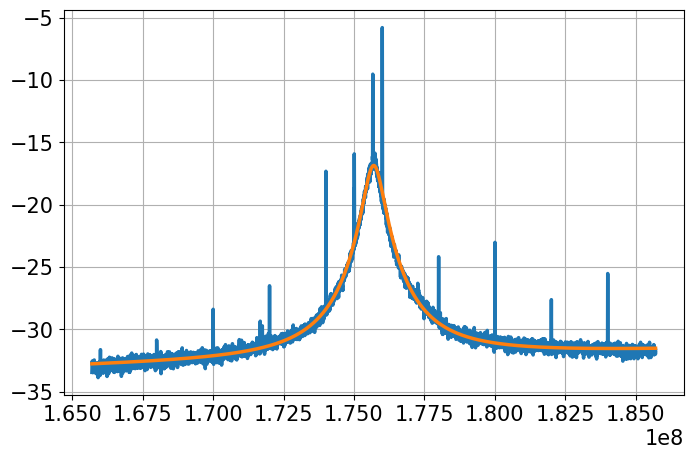

In [12]:
plot(noise_f, W_to_dBm(noise_p*1e-3)) 
plot(noise_f, get_noise_spectrum(noise_f, *popt_noise))

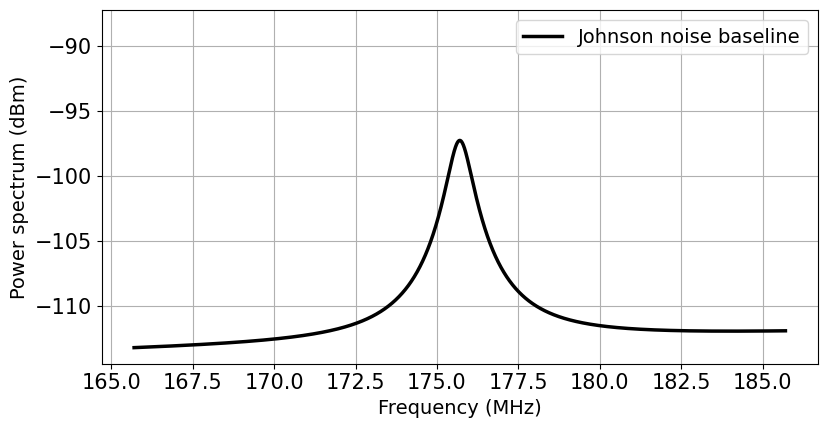

In [62]:
from matplotlib.animation import FuncAnimation, PillowWriter

duration_s = 30
n_per_phase = 50
fz = 175.7

def sci(x, digits=1):
    exp = int(np.floor(np.log10(x)))
    return f'{x / 10**exp:.{digits}f} \\times 10^{{{exp}}}'

N_lo, N_hi = 1, 1e5
Q_hi, Q_lo = 1e8, 10
T_lo, T_hi = 10, 1000

N_down = np.logspace(np.log10(N_hi), np.log10(N_lo), n_per_phase)
Q_scan = np.logspace(np.log10(Q_hi), np.log10(Q_lo), n_per_phase)
N_up = np.logspace(np.log10(N_lo), np.log10(N_hi), n_per_phase)
T_scan = np.logspace(np.log10(T_lo), np.log10(T_hi), n_per_phase)
assert T_scan[0] < T_scan[-1]
hold = np.ones(n_per_phase)

N_seq = np.concatenate([N_down, N_lo * hold, N_up, N_hi * hold])
Q_seq = np.concatenate([Q_hi * hold, Q_scan, Q_lo * hold, Q_lo * hold])
T_seq = np.concatenate([T_lo * hold, T_lo * hold, T_lo * hold, T_scan])

sim_spectra = [get_signal_spectrum(freq_sig, Ne, Te, fz, Qi, *popt_noise)
               for Ne, Te, Qi in zip(N_seq, T_seq, Q_seq)]
baseline = get_signal_spectrum(freq_sig, 1, 1, fz, 0.1, *popt_noise)
n_frames = len(sim_spectra)
fps = n_frames / duration_s

y_all = np.concatenate(sim_spectra + [baseline])
y_lo, y_hi = np.nanmin(y_all), np.nanmax(y_all)
pad = 0.05 * (y_hi - y_lo)

fig_bl, ax_bl = plt.subplots(figsize=(8.5, 4.5))
plot_ax(ax_bl, freq_sig/1e6, baseline, c=black, label='Johnson noise baseline',
        xlabel='Frequency (MHz)', ylabel='Power spectrum (dBm)')
ax_bl.set_ylim(y_lo - pad, y_hi + pad)
fig_bl.tight_layout()

fig, ax = plt.subplots(figsize=(8.5, 4.5))

def update(k):
    ax.cla()
    plot_ax(ax, freq_sig/1e6, baseline, c=black, label='Johnson noise baseline')
    plot_ax(ax, freq_sig/1e6, sim_spectra[k], c=blue,
            label=f'$Q_e = {sci(Q_seq[k])}$\n$N_e = {sci(N_seq[k])}$\n$E/k_B$ = {T_seq[k]:.0f} K',
            xlabel='Frequency (MHz)', ylabel='Power spectrum (dBm)')
    ax.set_ylim(y_lo - pad, y_hi + pad)
    ax.legend(loc='upper right')
    return []

anim = FuncAnimation(fig, update, frames=range(n_frames), blit=False)
anim.save('simulated_spectrum_evolution_Q.gif', writer=PillowWriter(fps=fps))
plt.close(fig)

In [13]:
popt, perr, pcov, rms = fit_db(
    lambda freq, n, T, f0, Q: get_signal_spectrum(freq, n, T, f0, Q, *popt_noise), 
    signal_f_2, signal_p_2,
    p0=[10000, 3000, 220.7, 15],
    lo=[1000, 100, 100, 1],
    hi=[100000, 0.3*e/kB, 300, 1000],
    data_in_db=False,
    n_restarts=200)

In [14]:
def sci(x, sig=2):
    exp = int(np.floor(np.log10(abs(x))))
    mant = x / 10**exp
    return rf'{mant:.{sig}f} \times 10^{{{exp}}}'

def sci_pm(v, err, sig=1):
    exp = int(np.floor(np.log10(abs(v))))
    return rf'({v/10**exp:.{sig}f} \pm {err/10**exp:.{sig}f}) \times 10^{{{exp}}}'

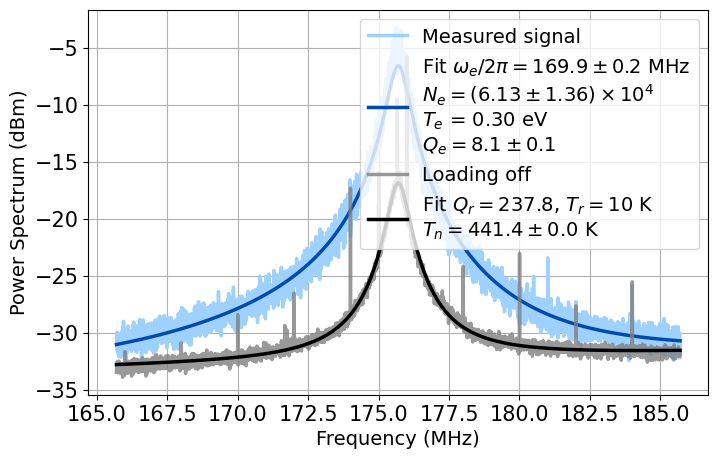

In [15]:
# plt.figure(figsize=(3.375*2.5, 2.1*2.5))
plt.figure()
plot(signal_f_2/1e6, W_to_dBm(signal_p_2*1e-3), c=light_blue, label='Measured signal') 
plot(signal_f_2/1e6, get_signal_spectrum(noise_f, *popt, *popt_noise), c=blue,
     label=f'Fit $\omega_e/2\pi = {popt[2]:.1f} \pm {perr[2]:.1f}$ MHz\n$N_e = {sci_pm(popt[0],perr[0],2)}$\n$T_e$ = {popt[1]*kB/e:.2f} eV\n$Q_e = {popt[3]:.1f}\pm{perr[3]:.1f}$')

plot(noise_f/1e6, W_to_dBm(noise_p*1e-3), c='grey', alpha=0.8, label='Loading off') 
plot(noise_f/1e6, get_noise_spectrum(noise_f, *popt_noise), c=black, label=f'Fit $Q_r = {popt_noise[2]:.1f}$, $T_r = 10$ K\n$T_n={popt_noise[0]:.1f}\pm{perr_noise[0]:.1f}$ K', 
     xlabel='Frequency (MHz)', ylabel="Power Spectrum (dBm)")

In [16]:
def codes_to_volts(d, vpp=1.0, full_scale_code=32768):
    return np.asarray(d, dtype=float) / full_scale_code * (vpp / 2)

def iq_power_spectrum_dbm(I, Q, fs, f0, span, rbw, vpp=2.0, full_scale_code=32768, R=50.0):
    x = codes_to_volts(I, vpp, full_scale_code) - 1j * codes_to_volts(Q, vpp, full_scale_code)
    if span > fs:
        raise ValueError("span exceeds IQ sample rate")
    enbw_bins = 1.5
    nfft = int(np.ceil(enbw_bins * fs / rbw))
    if nfft > len(x):
        raise ValueError(f"need at least {nfft} samples for rbw={rbw}")
    w = np.hanning(nfft)
    step = nfft // 2
    nseg = 1 + (len(x) - nfft) // step
    segs = np.stack([x[i * step:i * step + nfft] * w for i in range(nseg)])
    X = np.fft.fftshift(np.fft.fft(segs, axis=1), axes=1)
    p_watts = np.mean(np.abs(X) ** 2, axis=0) / np.sum(w) ** 2 / (2 * R)
    freq = f0 + np.fft.fftshift(np.fft.fftfreq(nfft, 1 / fs))
    mask = np.abs(freq - f0) <= span / 2
    p_dbm = 10 * np.log10(p_watts[mask] / 1e-3 + 1e-30)
    rbw_actual = enbw_bins * fs / nfft
    return freq[mask], p_dbm, rbw_actual

def bandpass_iq(I, Q, fs, f0, fc, bw, vpp=1.0, full_scale_code=32768, conj=False, taper=0.1, shift_to_dc=True):
    x = codes_to_volts(I, vpp, full_scale_code) + 1j * codes_to_volts(Q, vpp, full_scale_code)
    if conj:
        x = np.conj(x)
    N = len(x)
    t = np.arange(N) / fs
    df_c = fc - f0
    if abs(df_c) + bw / 2 > fs / 2:
        raise ValueError("filter band outside IQ bandwidth")
    f = np.fft.fftfreq(N, 1 / fs)
    d = np.abs(f - df_c)
    edge = taper * bw / 2
    if edge > 0:
        H = np.clip((d - (bw / 2 - edge)) / (2 * edge), 0, 1)
        H = 0.5 * (1 + np.cos(np.pi * H))
    else:
        H = (d <= bw / 2).astype(float)
    y = np.fft.ifft(np.fft.fft(x) * H)
    if shift_to_dc:
        y = y * np.exp(-2j * np.pi * df_c * t)
    return t, y

In [17]:
fs = 552.96e6

iq_data = np.load('C:\\Users\\andrish\\Downloads/background_1.npz')
i1,q1 = iq_data['iq'].T
freq_bg, P_background_1, rbw_actual = iq_power_spectrum_dbm(i1, q1, fs, 175.7e6, 20e6, 5e3)
iq_data = np.load('C:\\Users\\andrish\\Downloads/background_2.npz')
i2,q2 = iq_data['iq'].T
freq_bg, P_background_2, rbw_actual = iq_power_spectrum_dbm(i2, q2, fs, 175.7e6, 20e6, 5e3)
P_background = 1/2 * (P_background_1 + P_background_2) 

iq_data = np.load('C:\\Users\\andrish\\Downloads/signal_electron.npz')
i,q = iq_data['iq'].T
freq_sig, P_sig, rbw_actual = iq_power_spectrum_dbm(i, q, fs, 175.7e6, 20e6, 5e3)

In [18]:
# t_sig, sig_filtered = bandpass_iq(i, q, fs, 175.7e6, 175.7e6, 20e6, conj=True)
# t_bg, bg_filtered = bandpass_iq(i2, q2, fs, 175.7e6, 175.7e6, 20e6, conj=True)

In [19]:
file = np.load('fft_time_data_20MHz.npz')
t_sig, sig_filtered, t_bg, bg_filtered = file['t_sig'], file['sig_filtered'], file['t_bg'], file['bg_filtered']

In [20]:
# np.savez('fft_time_data_20MHz.npz', t_sig=t_sig, sig_filtered=sig_filtered, t_bg=t_bg, bg_filtered=bg_filtered, bw=20e6)

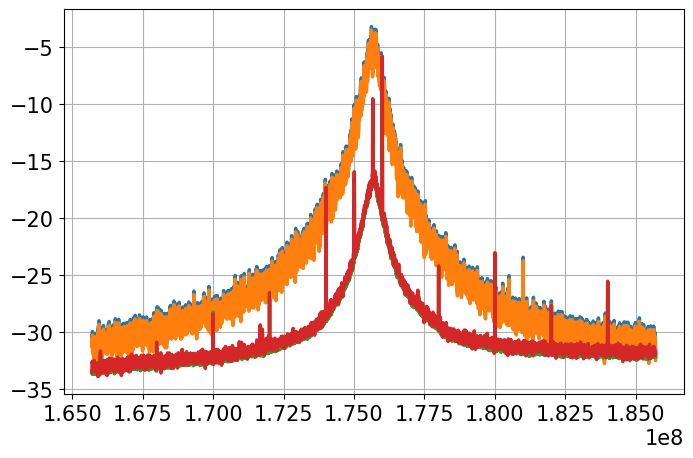

In [21]:
plot(freq_sig, W_to_dBm(signal_p_2*1e-3))#-P_sig-80)
plot(freq_sig, P_sig+80)
plot(freq_bg, P_background+80)
plot(noise_f, W_to_dBm(noise_p*1e-3))

In [22]:
# popt_noise, perr_noise, pcov, rms = fit_db(
#     get_noise_spectrum,freq_bg, P_background, #dBm_to_W(P_background+80)*1e3, #dBm_to_W(P_background)*1e3,
#     p0=[55, 103, 300],
#     lo=[1, 1, 100],
#     hi=[1000, 120, 1000],
#     data_in_db=1,
#     n_restarts=200)


In [23]:
popt_noise, perr_noise, pcov, rms = fit_db(
    get_noise_spectrum, freq_bg, P_background,
    p0=[55, 103, 300, 1, 0, 0],
    lo=[1, 1, 100, 0, -np.pi, -0.2],
    hi=[1000, 120, 1000, 20, np.pi, 0.2],
    data_in_db=1,
    n_restarts=200)

popt, perr, pcov, rms = fit_db(
    lambda freq, n, T, f0, Q: get_signal_spectrum(freq, n, T, f0, Q, *popt_noise), 
    freq_sig, P_sig, #dBm_to_W(P_sig+80)*1e3,
    p0=[10000, 3000, 220.7, 15],
    lo=[1000, 100, 100, 1],
    hi=[1000000, 0.3*e/kB, 300, 1000],
    data_in_db=1,#True,
    n_restarts=200)

C:\Users\andrish\AppData\Local\Temp\ipykernel_12992\2171722989.py:42: RuntimeWarning: invalid value encountered in divide
  return (Z_tank / (Z_tank+Z_ele))
C:\Users\andrish\AppData\Local\Temp\ipykernel_12992\2171722989.py:28: RuntimeWarning: invalid value encountered in divide
  return Zlc / (Zlc+R)


In [24]:
popt_noise, popt

(array([ 4.25616504e+02,  1.65850843e+01,  2.38730690e+02,  4.86777781e-02,
        -1.16305083e+00,  6.49742163e-02]),
 array([6.27129461e+04, 3.48135544e+03, 1.69514989e+02, 7.85901744e+00]))

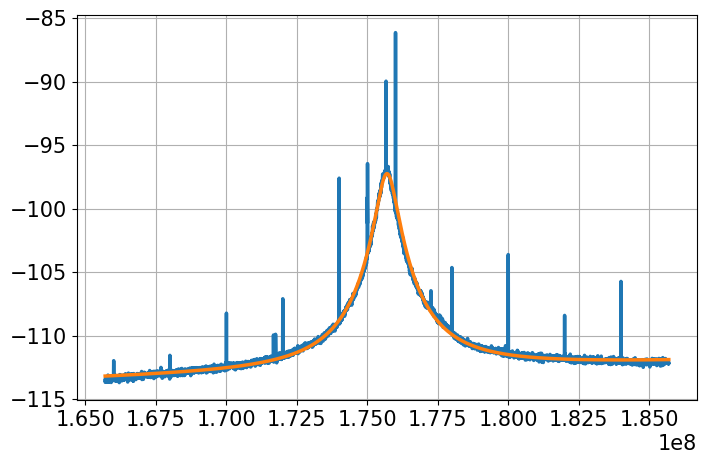

In [25]:
plot(freq_bg, P_background) 
plot(freq_bg, get_noise_spectrum(freq_bg, *popt_noise))

In [92]:
idata, q = iq_data['iq'].T
t = np.arange(len(idata)) / fs

window_t = 0.5e-3
N_windows = 30
N_win = int(round(window_t * fs))
starts = np.linspace(0, len(idata) - N_win, N_windows).astype(int)
hop_t = (starts[1] - starts[0]) / fs
print(f'window = {N_win/fs*1e3:.3f} ms, hop = {hop_t*1e3:.3f} ms, overlap = {100*(1 - hop_t*fs/N_win):.1f} %')

all_n, all_Q, all_t, all_f = [], [], [], []
all_n_err, all_Q_err, all_f_err = [], [], []
all_freq_t, all_P_sig_t = [], []
all_popt = []
for idx in starts:
    freq_sig_t, P_sig_t, rbw_actual = iq_power_spectrum_dbm(
        idata[idx:idx+N_win], q[idx:idx+N_win], fs, 175.7e6, 20e6, 5e3)
    all_freq_t.append(freq_sig_t)
    all_P_sig_t.append(P_sig_t)
    popt_t, perr_t, pcov_t, rms_t = fit_db(
        lambda freq, n, T, f0, Q: get_signal_spectrum(freq, n, T, f0, Q, *popt_noise),
        freq_sig_t, P_sig_t,
        p0=[10000, 300, 175.7, 15],
        lo=[1000, 100, 100, 1],
        hi=[1e6, 1000, 300, 1000],
        data_in_db=True,
        n_restarts=200)
    all_n.append(popt_t[0])
    all_Q.append(popt_t[-1])
    all_t.append(idx / fs)
    all_f.append(popt_t[2])
    all_f_err.append(perr_t[2])
    all_n_err.append(perr_t[0])
    all_Q_err.append(perr_t[-1])
    all_popt.append(popt_t)
    print(popt_t, rbw_actual)

window = 0.500 ms, hop = 0.328 ms, overlap = 34.5 %
[8.73546274e+04 1.00000000e+03 1.73137350e+02 1.56068691e+01] 5000.0
[4.60472386e+05 1.00000000e+03 1.72000938e+02 1.13249420e+01] 5000.0
[5.85236958e+05 1.00000000e+03 1.71820271e+02 1.05257388e+01] 5000.0
[3.60964035e+05 1.00000000e+03 1.71836399e+02 1.19491334e+01] 5000.0
[2.64769865e+05 1.00000000e+03 1.72127796e+02 1.13230389e+01] 5000.0
[2.01136754e+05 1.00000000e+03 1.72357837e+02 1.15121138e+01] 5000.0
[1.47464948e+05 1.00000000e+03 1.72019579e+02 1.18482687e+01] 5000.0
[1.07246946e+05 1.00000000e+03 1.72860878e+02 1.45493735e+01] 5000.0
[8.86618487e+04 1.00000000e+03 1.73055411e+02 1.44809600e+01] 5000.0
[8.51159593e+04 1.00000000e+03 1.73282565e+02 1.36165163e+01] 5000.0
[6.78881593e+04 1.00000000e+03 1.73749071e+02 1.51508929e+01] 5000.0
[5.98204776e+04 1.00000000e+03 1.73340356e+02 1.48975316e+01] 5000.0
[6.08344233e+04 9.99999999e+02 1.72726375e+02 1.34772081e+01] 5000.0
[5.26233069e+04 1.00000000e+03 1.72914633e+02 1.407

In [26]:
def envelope_fs(y, fs, t0, n_points=4000, step=None):
    """like :func:`sa_rfsoc_corr._envelope`, but the time axis is built from
    ``fs`` instead of being passed in — a full ``t`` array for a 55 M-sample
    record is 440 MB that is thrown away immediately after binning."""
    y = np.asarray(y)
    if step is None:
        step = 1 if len(y) <= 2 * n_points else int(np.ceil(len(y) / n_points))
    if step <= 1 or len(y) <= step:
        return t0 + np.arange(len(y)) / fs, y, y, y
    k = (len(y) // step) * step
    m = y[:k].reshape(-1, step)
    return (t0 + np.arange(m.shape[0]) * step / fs, m.mean(1))

def envelope_power_fs(i, q, fs, t0, n_points=4000, step=None):
    i = np.asarray(i)
    q = np.asarray(q)
    if step is None:
        step = 1 if len(i) <= 2 * n_points else int(np.ceil(len(i) / n_points))
    if step <= 1 or len(i) <= step:
        return t0 + np.arange(len(i)) / fs, i.astype(float)**2 + q.astype(float)**2
    k = (len(i) // step) * step
    mi = i[:k].reshape(-1, step).astype(float, copy=False)
    mq = q[:k].reshape(-1, step).astype(float, copy=False)
    p = (np.einsum('ij,ij->i', mi, mi) + np.einsum('ij,ij->i', mq, mq)) / step
    return t0 + np.arange(p.size) * step / fs, p

def envelope_power(t, i, q, n_points=4000, step=None):
    t = np.asarray(t)
    i = np.asarray(i)
    q = np.asarray(q)
    if step is None:
        step = 1 if len(i) <= 2 * n_points else int(np.ceil(len(i) / n_points))
    if step <= 1 or len(i) <= step:
        return t, i.astype(float)**2 + q.astype(float)**2
    k = (len(i) // step) * step
    mi = i[:k].reshape(-1, step).astype(float, copy=False)
    mq = q[:k].reshape(-1, step).astype(float, copy=False)
    p = (np.einsum('ij,ij->i', mi, mi) + np.einsum('ij,ij->i', mq, mq)) / step
    t_deci = t[:k].reshape(-1, step).mean(1)
    return t_deci, p

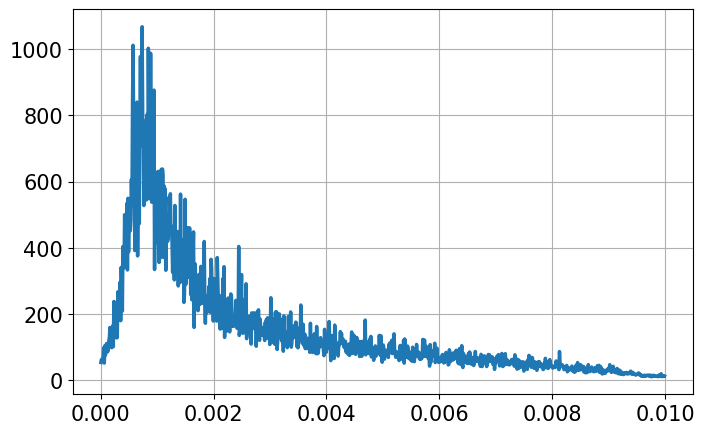

In [43]:
N_points = 1000
# t_sig_deci, sig_filtered_deci_i = envelope_fs(i, fs, 0, n_points=N_points) 
# t_sig_deci, sig_filtered_deci_q = envelope_fs(q, fs, 0, n_points=N_points) 
# t_bg_deci, bg_filtered_deci = envelope_fs((i2+1j*q2)[np.where(t_bg <= t_sig[-1])], fs, 0, n_points=N_points)
t_sig_deci, p_deci = envelope_power(t_sig, sig_filtered.real, sig_filtered.imag, n_points=N_points)
plot(t_sig_deci, p_deci/100*1e12)

In [93]:
all_n = np.array(all_n) 
idx = np.where((all_n < 9e5) & (np.array(all_Q) < 100) )
all_np = all_n[idx]
all_tp = np.array(all_t)[idx]
all_fp = np.array(all_f)[idx]
all_Qp = np.array(all_Q)[idx] 
all_Q_errp = np.array(all_Q_err)[idx] 
all_f_errp = np.array(all_f_err)[idx] 
all_n_errp = np.array(all_n_err)[idx]

In [104]:
from matplotlib.animation import FuncAnimation, PillowWriter

duration_s = 15
max_fps = 50
frames = list(idx[0])
if len(frames) > duration_s * max_fps:
    frames = frames[::int(np.ceil(len(frames) / (duration_s * max_fps)))]
fps = len(frames) / duration_s

fft_window_t = all_t[1] - all_t[0]
y_all = np.concatenate([np.ravel(all_P_sig_t[i]) for i in frames] + [np.ravel(P_background)])
y_lo, y_hi = np.nanmin(y_all), np.nanmax(y_all)
pad = 0.05 * (y_hi - y_lo)

fig, ax = plt.subplots(nrows=2, figsize=(10, 9))

def update(i):
    ax[0].cla()
    ax[1].cla()
    
    plot_ax(ax[0], all_freq_t[i]/1e6, all_P_sig_t[i], c=light_blue, label='Signal spectrum')
    plot_ax(ax[0], all_freq_t[i]/1e6, get_signal_spectrum(all_freq_t[i], *all_popt[i], *popt_noise), c=blue)
    plot_ax(ax[0], freq_bg/1e6, P_background, c='grey', alpha=0.8, label='Loading off')
    plot_ax(ax[0], freq_bg/1e6, get_noise_spectrum(freq_bg, *popt_noise), c=black,
            xlabel='Frequency (MHz)', ylabel='Power Spectrum (dBm)')
    ax[0].axvspan(175.695, 175.705, color=light_blue, label='Power-detection window')
    ax[0].set_ylim(y_lo - pad, y_hi + pad)
    ax[0].legend()
    t_sig_deci, p_sig_deci = envelope_power(t_sig, sig_filtered.real, sig_filtered.imag, n_points=N_points) 
    t_bg_deci, p_bg_deci = envelope_power(t_bg, bg_filtered.real, bg_filtered.imag, n_points=N_points)
    t_idx = np.where(t_bg_deci <= max(t_sig_deci))
    plot_ax(ax[1], t_sig_deci*1e3, p_deci/100*1e9, xlabel='t (ms)', ylabel='Detection power (nW)', label="Measured signal")
    plot_ax(ax[1], t_bg_deci[t_idx]*1e3, p_bg_deci[t_idx]/100*1e9, c='grey', alpha=0.8, 
        label='Loading off', xlabel='Detection Time (ms)', ylabel='Detection Power (nW)')
    ax[1].axvspan(all_t[i]*1e3, (all_t[i] + fft_window_t)*1e3, color=light_blue, label='FFT window')
    
    ax[1].legend()
    return []

anim = FuncAnimation(fig, update, frames=frames, blit=False)
anim.save('spectrum_evolution.gif', writer=PillowWriter(fps=fps))
plt.close(fig)

In [ ]:
# np.savez('windowed_fft_data.npz', all_n=all_n, all_np=all_np, all_tp=all_tp, all_fp=all_fp, all_Qp=all_Qp, 
#          all_Q_errp=all_Q_errp, all_f_errp=all_f_errp, all_n_errp=all_n_errp)

In [ ]:
# np.savez('decimated_time_data.npz', t_sig_deci=t_sig_deci, t_bg_deci=t_bg_deci, sig_filtered_deci=sig_filtered_deci,
#          bg_filtered_deci=bg_filtered_deci
#         # )

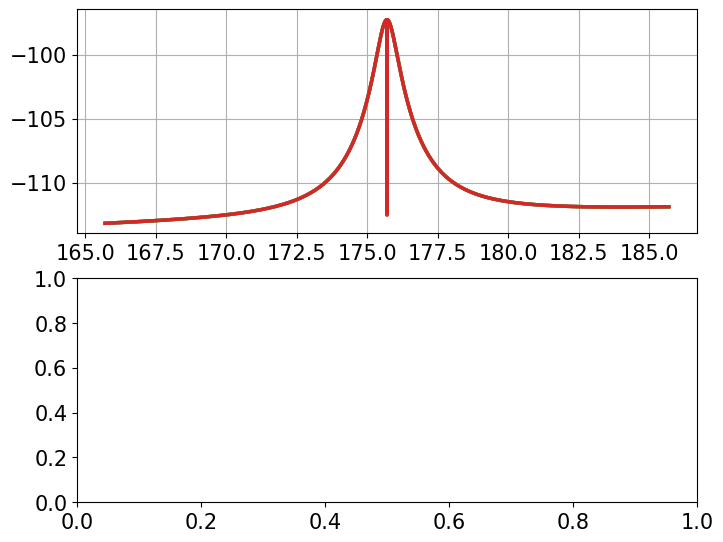

In [56]:
fig, ax = two_row_figs() 
for Q in [10, 100, 1e4, 1e8]:
    plot_ax(ax[0], freq_sig/1e6, get_signal_spectrum(freq_sig, 100, 10, 175.7, Q, *popt_noise))

In [54]:
from matplotlib.animation import FuncAnimation, PillowWriter

tau = 6.6e-3
T0 = 1e3
T_floor = 10
t_end = 60e-3
window_t = 1e-3
N_windows = 100
duration_s = 10

def Te_of_t(t):
    return T_floor + (T0 - T_floor) * np.exp(-t / tau)

def Te_window_avg(t_start, W):
    return T_floor + (T0 - T_floor) * tau / W * (np.exp(-t_start / tau) - np.exp(-(t_start + W) / tau))

t_starts = np.linspace(0, t_end - window_t, N_windows)
Te_win = Te_window_avg(t_starts, window_t)
Q = np.logspace(8, 0, 100)
all_N = np.logspace(0, 5, 10)
sim_spectra = [get_signal_spectrum(freq_sig, Ne, 10, 175.7, 1e8, *popt_noise) for Ne in all_N] + [get_signal_spectrum(freq_sig, 100000, 10, 175.7, Qi, *popt_noise) for Qi in Q] + [get_signal_spectrum(freq_sig, 100000, Te, 175.7, 10, *popt_noise) for Te in Te_win]
noise_spec = get_noise_spectrum(freq_sig, *popt_noise)
all_N_display = list(all_N) + [100000]*(len(Q)+len(Te_win))
Te_win_display = [10]*(len(Q)+len(all_N))+list(Te_window_avg(t_starts, window_t))
Q_display = list(Q) + [10]*len(Te_win)

y_all = np.concatenate(sim_spectra + [noise_spec])
y_lo, y_hi = np.nanmin(y_all), np.nanmax(y_all)
pad = 0.05 * (y_hi - y_lo)
t_fine = np.linspace(0, t_end, 2000)

fig, ax = plt.subplots(nrows=1, figsize=(8.5, 4.5))

def update(k):
    ax.cla()
    # ax[1].cla()
    # plot_ax(ax[0], freq_sig/1e6, noise_spec, c=black, label='Noise only')
    plot_ax(ax, freq_sig/1e6, sim_spectra[k], c=blue,
            label=f'$N_e = {sci(all_N_display[k])}$\n$E/k_B$ = {Te_win[k]:.0f} K\n$Q_e = {sci(Q[k])}$',
            xlabel='Frequency (MHz)', ylabel='Power spectrum (dBm)')
    ax.axvspan(175.65, 175.75, color=light_red, label='Power-detection window')
    ax.set_ylim(y_lo - pad, y_hi + pad)
    ax.legend()
    
    return []

anim = FuncAnimation(fig, update, frames=range(N_windows), blit=False)
anim.save('simulated_spectrum_evolution_Q.gif', writer=PillowWriter(fps=N_windows / duration_s))
plt.close(fig)

In [50]:
Te_window_avg(t_starts, window_t)

array([928.64863895, 849.33239754, 776.8643306 , 710.65316585,
       650.15868157, 594.88729883, 544.38805437, 498.24892116,
       456.09344663, 417.57768118, 382.38737187, 350.23539838,
       320.85943041, 294.01978728, 269.49748239, 247.09243645,
       226.62184505, 207.91868714, 190.83036229, 175.2174456 ,
       160.95255014, 147.91928758, 136.01131859, 125.13148516,
       115.19101796, 106.10881196,  97.8107648 ,  90.2291721 ,
        83.30217508,  76.97325587,  71.19077636,  65.90755688,
        61.08049124,  56.67019507,  52.64068444,  48.95908227,
        45.5953501 ,  42.52204301,  39.71408564,  37.14856767,
        34.80455685,  32.66292823,  30.7062081 ,  28.91843143,
        27.28501163,  25.79262151,  24.42908454,  23.18327553,
        22.04502983,  21.00506041,  20.05488208,  19.18674227,
        18.39355776,  17.66885691,  17.00672682,  16.40176513,
        15.8490359 ,  15.34402939,  14.88262521,  14.46105872,
        14.07589034,  13.72397744,  13.40244875,  13.10

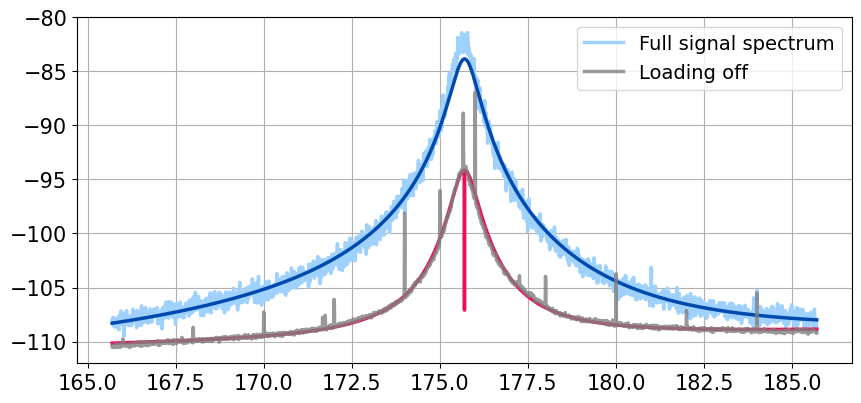

In [85]:
fig, ax = plt.subplots(figsize=(10,4.5))
plot_ax(ax, freq_sig/1e6, P_sig, c=light_blue, label='Full signal spectrum') 
plot_ax(ax, freq_sig/1e6, get_signal_spectrum(freq_sig, *popt, *popt_noise), c=blue)
plot_ax(ax, freq_sig/1e6, get_signal_spectrum(freq_sig, 1, 1, 175.7, 1e8, *popt_noise), c=red)

plot_ax(ax, freq_bg/1e6, P_background, c='grey', alpha=0.8, label='Loading off') 
# plot_ax(ax, freq_bg/1e6, get_noise_spectrum(freq_bg, *popt_noise), c=black, 
     # xlabel='Frequency (MHz)', ylabel="Power Spectrum (dBm)")

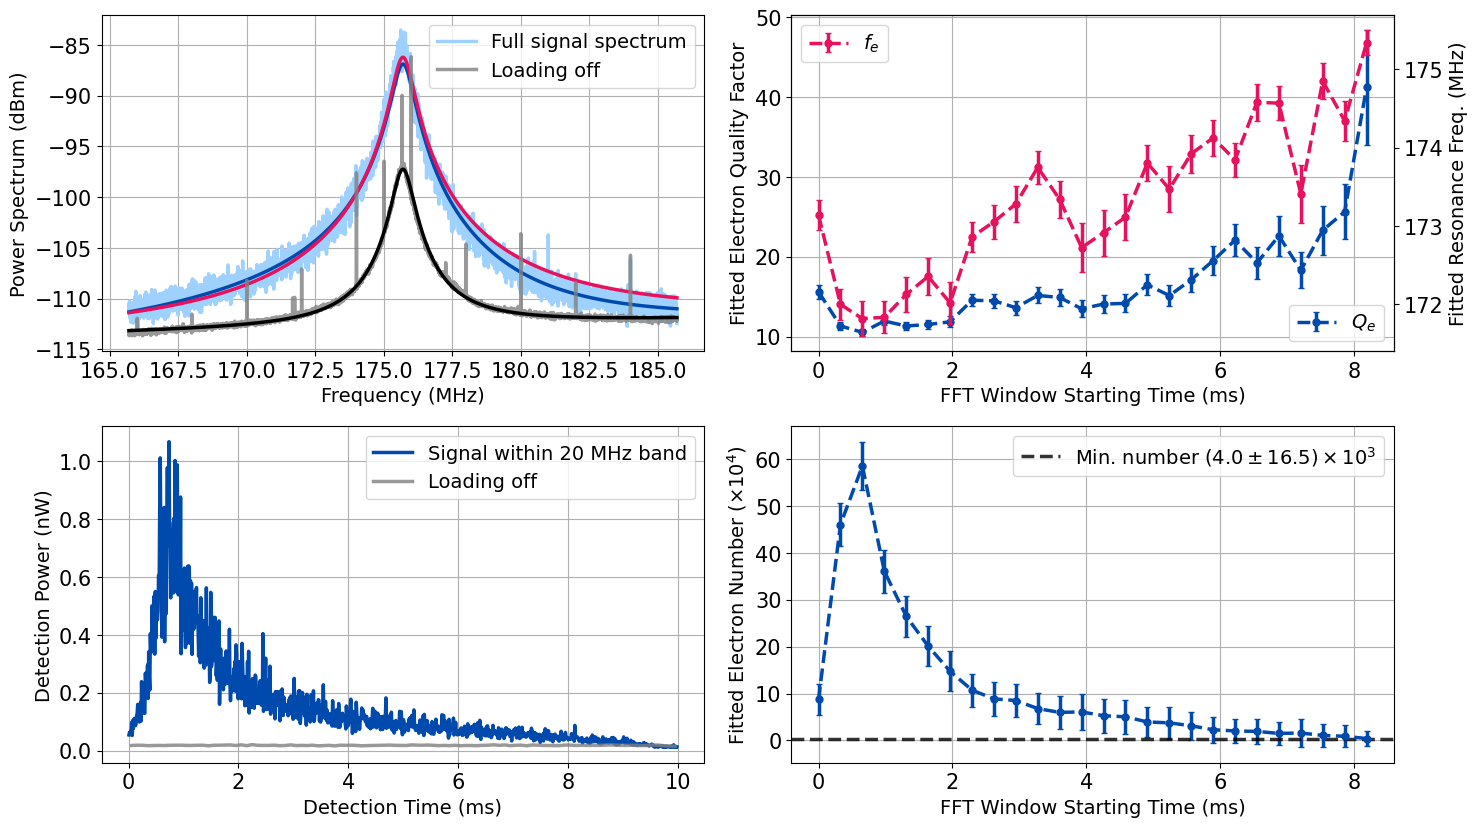

In [101]:
# plt.figure(figsize=(3.375*2.5, 2.1*2.5))
# plt.figure(figsize=(4.0*2, 2.5*2)) 
fig, ax = plt.subplots(figsize=(15,8.5), ncols=2, nrows=2)


plot_ax(ax[0][0], freq_sig/1e6, P_sig, c=light_blue, label='Full signal spectrum') 
plot_ax(ax[0][0], freq_sig/1e6, get_signal_spectrum(freq_sig, *popt, *popt_noise), c=blue)
plot_ax(ax[0][0], freq_sig/1e6, get_signal_spectrum(freq_sig, popt[0], 2300e3, popt[2], 0.01, *popt_noise), c=red)

plot_ax(ax[0][0], freq_bg/1e6, P_background, c='grey', alpha=0.8, label='Loading off') 
plot_ax(ax[0][0], freq_bg/1e6, get_noise_spectrum(freq_bg, *popt_noise), c=black, 
     xlabel='Frequency (MHz)', ylabel="Power Spectrum (dBm)")


ax01 = ax[0][1].twinx()
plot_ax_errbar(ax[0][1], all_tp*1e3, all_Qp, yerr=all_Q_errp, fmt='o--', markersize=5, c=blue, label=r'$Q_e$',
               ylabel=r'Fitted Electron Quality Factor', xlabel='FFT Window Starting Time (ms)')
plot_ax_errbar(ax01, all_tp*1e3, all_fp, yerr=all_f_errp, fmt='o--', markersize=5, c=red, label=r'$f_e$',
               ylabel=r'Fitted Resonance Freq. (MHz)', xlabel='FFT Window Starting Time (ms)')
# plot_ax(ax[1][0], t_sig_deci, 10*np.log10(np.abs(sig_filtered_deci)**2/100*1e3+1e-30), c=blue, label='Measured signal') 
# plot_ax(ax[1][0], t_bg_deci, 10*np.log10(np.abs(bg_filtered_deci)**2/100*1e3+1e-30), c='grey', alpha=0.8, label='Loading off') 
# ax[1][0].set_yscale('log')
ax[0][1].legend(loc='lower right')
ax01.grid(False)
ax01.legend()

t_sig_deci, p_sig_deci = envelope_power(t_sig, sig_filtered.real, sig_filtered.imag, n_points=N_points) 
t_bg_deci, p_bg_deci = envelope_power(t_bg, bg_filtered.real, bg_filtered.imag, n_points=N_points)
t_idx = np.where(t_bg_deci <= max(t_sig_deci))
plot_ax(ax[1][0], t_sig_deci*1e3, p_sig_deci/100*1e9, c=blue, label='Signal within 20 MHz band') 
plot_ax(ax[1][0], t_bg_deci[t_idx]*1e3, p_bg_deci[t_idx]/100*1e9, c='grey', alpha=0.8, 
        label='Loading off', xlabel='Detection Time (ms)', ylabel='Detection Power (nW)')

plot_ax_errbar(ax[1][1], all_tp*1e3, all_np/1e4, yerr=all_n_errp/1e4, fmt='o--', markersize=5, c=blue,
               ylabel=r'Fitted Electron Number ($\times 10^4$)', xlabel='FFT Window Starting Time (ms)')
# ax[1][1].set_yscale('log') 
ax[1][1].axhline(min(all_np)/1e4, linestyle='--', c=black, alpha=0.8, label=f'Min. number ${sci_pm(all_np[-1], all_n_errp[-1])}$')
ax[1][1].legend()

plt.tight_layout()
plt.show()

In [15]:
Cr = 2.97e-12 
f0 = 175.7e6 
Z0 = 1/(2*np.pi*f0 * Cr) 

In [16]:
Qe = popt[3] 
Qr = popt_noise[2] 
we = popt[2] * 1e6
wr = 175.7e6 
kappa_e = we / Qe 
kappa_r = wr / Qr 


In [17]:
# we = wr
# kappa_e = 0
Z0 = 1/(2*np.pi*f0 * Cr)  
(kappa_r/2 * (kappa_e + kappa_r)/2) / ((wr - we)**2 + ((kappa_e + kappa_r)/2)**2)

np.float64(0.025710624954381273)

In [18]:
kappa_e, Qe, Qr, we, wr, 

(np.float64(25659154.07630193),
 np.float64(6.6911781601794695),
 np.float64(236.9791273578436),
 np.float64(171689971.36403146),
 175700000.0)

In [33]:
import pandas as pd
df = pd.read_csv(r"C:\\Users\\andrish\\Downloads/multi_electron_com_broadening_data/multi_electron_com_broadening_data/csv/linewidth_line_shapes.csv")

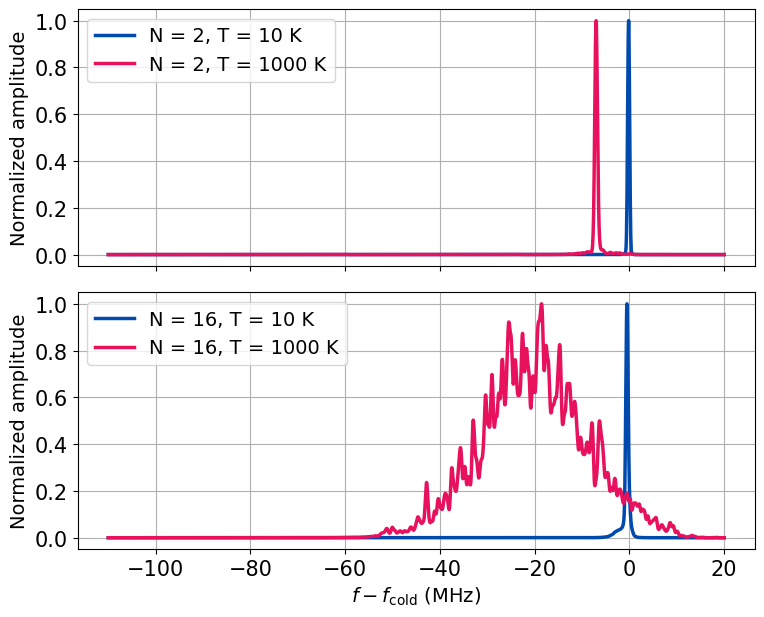

In [40]:
from edes.utils.plotting import two_row_size

def two_row_figs(**kwargs):
    fig, axs = plt.subplots(2, 1, figsize=two_row_size, **kwargs)
    return fig, axs


fig, axs = two_row_figs(sharex=True)

for ax, N in zip(axs, [2, 16]):
    for T, c in zip([10, 1000], [blue, red]):
        sub = df[(df['N'] == N) & (df['T_int_K'] == T)].sort_values('f_minus_f_cold_MHz')
        plot_ax(ax, sub['f_minus_f_cold_MHz'], sub['typical_single_cloud_per_MHz']/max(sub['typical_single_cloud_per_MHz']), c=c,
                label=f'N = {N}, T = {T} K',
                ylabel='Normalized amplitude',
                xlabel=r'$f - f_{\text{cold}}$ (MHz)' if ax is axs[-1] else None)

fig.tight_layout()

In [43]:
import pandas as pd
df = pd.read_csv(r"C://Users//andrish//Downloads/multi_electron_com_broadening_data/multi_electron_com_broadening_data/csv/linewidth_clouds.csv")

In [44]:
df

,N,T_int_K,cloud,N_left,n_lost,loss_times_ns,T_eff_K,E_int_x_K,E_int_y_K,E_int_z_K,t_meas_ns,measured,centre_shift_MHz,width_rms_MHz
0,2,10,1,2,0,NaN,9.875584,11.105449,5.995952,12.525351,3000.0,1,-0.085115,0.202292
1,2,10,2,2,0,NaN,10.082328,22.005244,6.392157,1.849581,3000.0,1,-0.240716,0.228931
2,2,10,3,2,0,NaN,1.501163,0.249078,1.992563,2.261847,3000.0,1,-0.025024,0.195973
3,2,10,4,2,0,NaN,4.758014,1.557765,2.528011,10.188267,3000.0,1,-0.096600,0.199929
4,2,10,5,2,0,NaN,5.402272,5.059535,8.802411,2.344870,3000.0,1,-0.103032,0.195284
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2395,16,1000,196,10,6,1.0860948;3.1816429;4.4486448;5.1767447;10.288...,612.886140,9249.509600,3398.322200,3900.093900,3000.0,1,-28.459050,15.295443
2396,16,1000,197,11,5,0.025956709;0.025956709;0.19465436;12.018122;1...,863.942290,9152.924600,10911.468000,5853.876500,3000.0,1,-18.098354,8.735250
2397,16,1000,198,11,5,0.012334386;0.071195771;2.7077441;9.3475875;23...,644.606550,5193.223800,11093.523000,3051.449500,3000.0,1,-11.382445,3.991405
2398,16,1000,199,8,8,0.020173831;0.020173831;0.62309555;0.95580322;...,511.966190,3889.682600,3993.047400,2868.560100,3000.0,1,-9.614292,3.322512


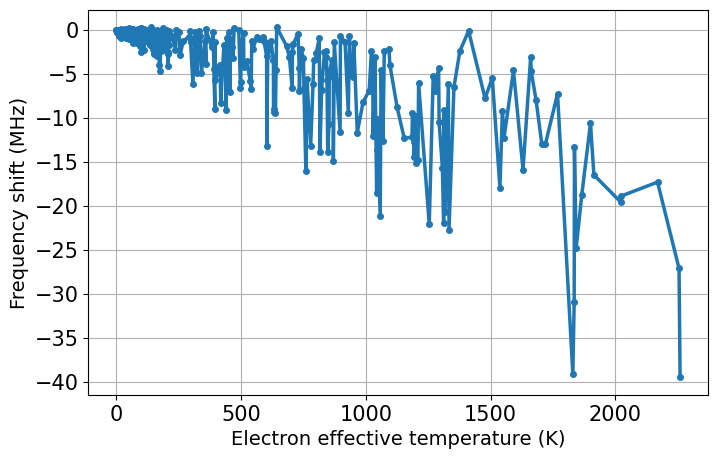

In [48]:
sub = df[(df['N'] == 2)].sort_values('T_eff_K')
plot(sub['T_eff_K'], sub['centre_shift_MHz'], '.-', xlabel='Electron effective temperature (K)', ylabel='Frequency shift (MHz)')

In [ ]:

for C in np.linspace(100e-12, 1e-12, 100): 
    P = 